# Costs and budgets

Node costs can change which group member is chosen. Prizes, signed weights, and budgets change what the objective measures.

Download {download}`this notebook <costs_and_budgets.ipynb>` to run it locally.
Install the example dependencies with `pip install steinerpy matplotlib ipykernel`.
All solves below use the default HiGHS backend.

In [1]:
import logging
import matplotlib.pyplot as plt
import networkx as nx
from steinerpy import Problem

# Keep the example output focused on results; solver errors still propagate.
logging.getLogger().setLevel(logging.WARNING)
logging.getLogger("steinerpy").setLevel(logging.WARNING)
plt.rcParams.update({"figure.dpi": 140, "font.size": 11, "figure.facecolor": "white"})

## Pay for selected nodes

Choose one of A or B and connect it to C. Without node costs, A is cheaper.
Charging 10 to select A makes B the better choice. Selected terminal nodes
also incur node costs; missing node costs are zero.

In [2]:
graph = nx.Graph()
graph.add_weighted_edges_from([("A", "C", 1), ("B", "C", 3)])
positions = {"A": (0, 1), "B": (0, -1), "C": (2, 0)}
groups = [["A", "B"], ["C"]]
edge_only = Problem(graph, groups=groups).get_solution(time_limit=30)
node_costs = {"A": 10}
with_nodes = Problem(graph, groups=groups, node_costs=node_costs).get_solution(time_limit=30)
print(f"Edge costs only: {edge_only.objective:g}; with node costs: {with_nodes.objective:g}")

Edge costs only: 1; with node costs: 3


In [3]:
assert edge_only.objective == 1 and with_nodes.objective == 3
assert edge_only.gap == with_nodes.gap == 0
assert set(with_nodes.selected_nodes) == {"B", "C"}
for solution in [edge_only, with_nodes]:
    chosen = graph.edge_subgraph(solution.edges)
    assert nx.is_connected(chosen)
    assert all(set(group) & set(chosen) for group in groups)

In [4]:
def draw(graph, positions, ax, title, solution=None, terminals=(), groups=(), root=None):
    """Plot original edges and highlight a returned selection at fixed positions."""
    ax.set_facecolor("white")
    arrow_options = {"arrowsize": 18} if graph.is_directed() else {}
    nx.draw_networkx_edges(graph, positions, ax=ax, edge_color="#b8bec5",
                           style="dashed", width=1.3, node_size=620, **arrow_options)
    if solution is not None:
        nx.draw_networkx_edges(graph, positions, ax=ax, edgelist=solution.edges,
                               edge_color="#007a78", width=3, node_size=620,
                               **arrow_options)
    marked = set(terminals) | {node for group in groups for node in group}
    if root is not None:
        marked.add(root)
    ordinary = [node for node in graph if node not in marked]
    nx.draw_networkx_nodes(graph, positions, ax=ax, nodelist=ordinary,
                           node_color="#f5f7fa", edgecolors="#374151", node_size=620)
    if terminals:
        nx.draw_networkx_nodes(graph, positions, ax=ax, nodelist=list(terminals),
                               node_shape="s", node_color="#ffdc8b",
                               edgecolors="#374151", node_size=620)
    for idx, group in enumerate(groups):
        nx.draw_networkx_nodes(graph, positions, ax=ax, nodelist=group,
                               node_shape=["s", "^"][idx % 2],
                               node_color=["#c2e4f5", "#ffd3a8"][idx % 2],
                               edgecolors="#374151", node_size=620)
    if root is not None:
        nx.draw_networkx_nodes(graph, positions, ax=ax, nodelist=[root],
                               node_shape="D", node_color="#dbcdf3",
                               edgecolors="#374151", node_size=620)
    nx.draw_networkx_labels(graph, positions, ax=ax, font_size=11,
                            font_color="#17212b")
    nx.draw_networkx_edge_labels(graph, positions, ax=ax,
                                 edge_labels=nx.get_edge_attributes(graph, "weight"),
                                 font_size=10, rotate=False)
    ax.set_title(title, color="#17212b", pad=12)
    ax.margins(0.25)
    ax.set_axis_off()

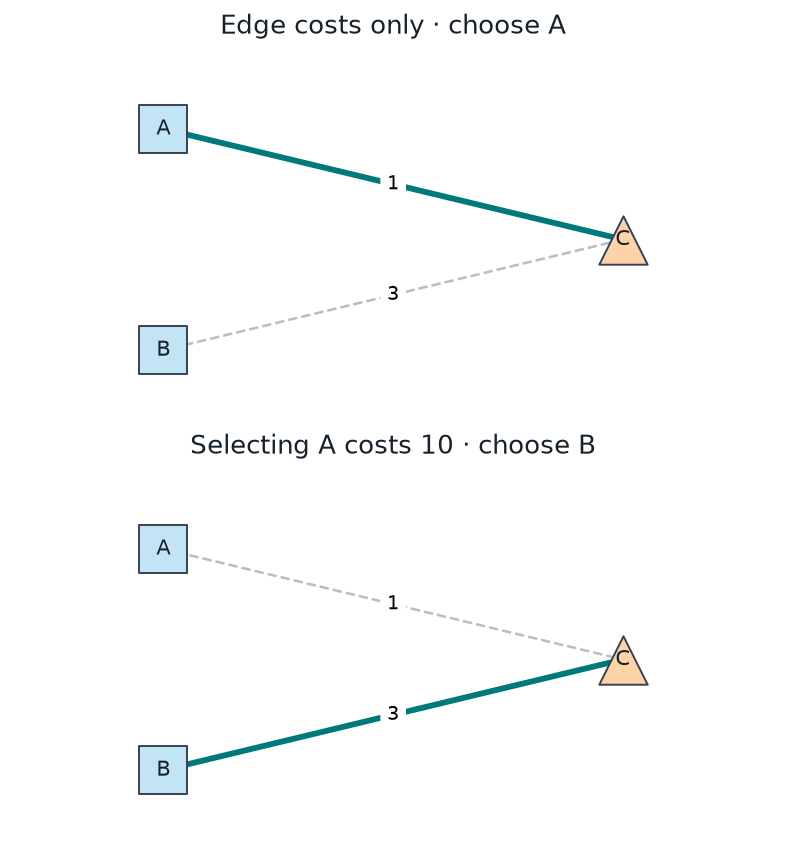

In [5]:
fig, axes = plt.subplots(2, 1, figsize=(5.5, 6), layout="constrained")
draw(graph, positions, axes[0], "Edge costs only · choose A", edge_only, groups=groups)
draw(graph, positions, axes[1], "Selecting A costs 10 · choose B", with_nodes, groups=groups)
plt.show()

## Prizes, weights, and a coverage budget

On the next graph, R is the starting node. A costs 1 to reach; B costs 4.
Give A a prize of 4 and B a prize of 2. Connecting A and omitting B costs
`1 + 2 = 3`, which is cheaper than collecting both prizes.

Signed weights instead maximize selected-node weight. Here including B
adds a weight of −2, so the best connected selection contains R and A.
Edge costs do not enter that objective; they can constrain it through a budget.

Finally, an edge budget without rewards maximizes terminal coverage.
A budget of 1 reaches A from R, so two of the three terminals count as covered,
including the root. These objective values have different meanings.

In [6]:
graph = nx.Graph()
graph.add_weighted_edges_from([("R", "A", 1), ("R", "B", 4)])
positions = {"R": (0, 0), "A": (2, 1), "B": (2, -1)}
prizes = {"A": 4, "B": 2}
weights = {"R": 0, "A": 4, "B": -2}
prize = Problem(graph, terminals=["R"], node_prizes=prizes).get_solution(time_limit=30)
weighted = Problem(graph, terminals=["R"], node_weights=weights).get_solution(time_limit=30)
budgeted = Problem(graph, terminals=["R", "A", "B"], budget=1).get_solution(time_limit=30)
print(f"Cost plus omitted prizes: {prize.objective:g}")
print(f"Selected signed weight: {weighted.objective:g}")
print(f"Terminal coverage: {budgeted.connected_terminals}/{budgeted.total_terminals}")

Cost plus omitted prizes: 3
Selected signed weight: 4
Terminal coverage: 2/3


In [7]:
assert prize.objective == 3 and weighted.objective == 4 and budgeted.objective == 2
for solution in [prize, weighted, budgeted]:
    assert solution.gap == 0
    assert {frozenset(edge) for edge in solution.edges} == {frozenset(("R", "A"))}
    assert nx.is_connected(graph.edge_subgraph(solution.edges))
assert prize.objective == 1 + prizes["B"]
assert weighted.objective == sum(weights[node] for node in weighted.selected_nodes)
assert sum(graph[u][v]["weight"] for u, v in budgeted.edges) <= 1
assert budgeted.connected_terminals == 2 and budgeted.total_terminals == 3

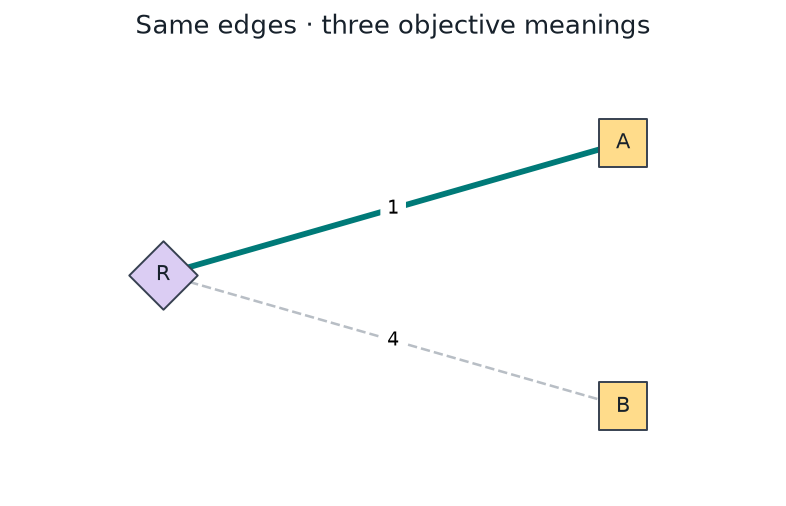

In [8]:
fig, ax = plt.subplots(figsize=(5.5, 3.5), layout="constrained")
draw(graph, positions, ax, "Same edges · three objective meanings", budgeted,
     terminals=["A", "B"], root="R")
plt.show()

## Combine rewards with a budget

With `node_weights`, a budget limits resources without changing the objective
into coverage. `node_budget` similarly limits the sum of `node_costs`.

In [9]:
limited = Problem(
    graph, terminals=["R"], node_weights={"A": 4, "B": 6}, budget=1,
).get_solution(time_limit=30)
print(f"Weight collected within budget: {limited.objective:g}")

Weight collected within budget: 4


In [10]:
assert limited.objective == 4 and limited.gap == 0
assert set(limited.selected_nodes) == {"R", "A"}
assert sum(graph[u][v]["weight"] for u, v in limited.edges) <= 1

Use either `node_prizes` or `node_weights`, not both. Mandatory terminals
still matter in reward models. Legacy prize and node-weighted classes have
different defaults; see [objective conventions](../reference/compatibility.md#objective-conventions).
Next, add [structural constraints](constraints.ipynb).